# Amazon Product Ratings: integrated team project

CAP 3764, Fall 2026, Team 6. **P1-b runnable skeleton**: collection, cleaning and EDA are connected. Feature engineering, models and model charts remain pending their owners' PRs and P1-c integration.

This notebook calls shared modules rather than reimplementing their analysis. Run from the repository root or `notebooks/` with the **Python (amazon-reviews)** kernel. Restart the kernel and run all cells in order. Outputs stay under ignored `data/`; existing report figures and teammates' datasets are preserved.

## 1. Project goal and question

Parker Fabian (Person 1) connects the team's workflow. We ask which product listing characteristics are associated with customer ratings and whether they can predict a product's average rating (1-5 stars). This is a regression question about associations, not causal effects.

The setup below imports the shared orchestration module. The default quick run uses the **first 5,000 All_Beauty entries**, not a representative random sample. Change `QUICK` to `False` to use all four collected categories; this takes more resources.

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
if not (root / "src").is_dir():
    root = root.parent
if not (root / "src" / "collect.py").is_file():
    raise RuntimeError("Open this notebook from the project root or notebooks folder")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import Image, display
import pandas as pd
import pyarrow.parquet as pq
from src import pipeline

QUICK = True
print("Mode:", "first 5,000 All_Beauty entries (smoke check)" if QUICK else "all four categories")

Mode: first 5,000 All_Beauty entries (smoke check)


C:\Users\Parker\Documents\Codex\2026-09-25\files-mentioned-by-the-user-team-2\work\miniconda3\envs\amazon-reviews\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data collection

Parker Fabian (Person 1) built `src.collect` for pinned Amazon Reviews 2023 product metadata from McAuley Lab. It preserves raw values and source category labels; see [notebook 01](01_collection_p1.ipynb) for collection verification and source details.

The wrapper below collects a separate quick sample or reuses the existing full raw table. A missing full table is built with the streaming shared collector.

In [2]:
raw_path = pipeline.run_collect(quick=QUICK)
print("Raw rows:", pq.ParquetFile(raw_path).metadata.num_rows)

All_Beauty: 5,000 rows


collect: 5,000 rows -> data\raw\pipeline_quick.parquet (first rows, not representative)


Raw rows: 5000


## 3. Cleaning and preprocessing

Michael Font (Person 2) built `src.clean.clean_products`; see [notebook 02](02_cleaning_p2.ipynb) for the cleaning decisions. Parker's wrapper calls that function in batches and saves all returned columns to a separate pipeline folder without changing raw inputs.

This runs the existing cleaning only. The later model split and fitted preprocessor belong to Person 2's Submission 2 work, not this stage.

In [3]:
clean_path = pipeline.run_clean(raw_path)
print("Cleaned rows:", pq.ParquetFile(clean_path).metadata.num_rows)
print("Output:", clean_path.relative_to(root))

clean: 5,000 rows -> 5,000 rows; data\processed\pipeline\quick\products_clean.parquet


Cleaned rows: 5000
Output: data\processed\pipeline\quick\products_clean.parquet


## 4. Exploratory data analysis

Rana Waleed Aftab (Person 3) built `src.stats` and Anthony Perez (Person 4) built `src.viz`; see [notebook 03](03_stats_p3.ipynb) and [notebook 04](04_viz_p4.ipynb). The calls below generate their numeric summaries, category comparisons, correlations and seven EDA charts.

Parker redirects these verification files into the ignored pipeline folder, leaving `reports/figures/` untouched. **Quick-mode tables and charts describe only the first All_Beauty records and must not be used as whole-project findings.** Skewness is named for its long tail: positive is right, negative is left.

In [4]:
table_paths = pipeline.run_eda(clean_path)
for name, path in table_paths.items():
    print(name)
    display(pd.read_csv(path, index_col=0))

eda: 5,000 rows -> 3 tables; data\processed\pipeline\quick\tables


numeric_summary


,count,n_missing,mean,median,std,min,25%,75%,max,skew
average_rating,5000.0,0.0,3.917,4.0,0.839,1.00,3.50,4.50,5.0,-1.182
rating_number,5000.0,0.0,62.919,11.0,489.765,1.00,4.00,31.00,27308.0,39.674
price_num,949.0,4051.0,25.076,16.8,29.121,0.59,9.98,27.99,295.0,3.963


rating_by_category


,n_products,mean_rating,diff_from_overall,median_rating,std_rating,pct_has_price,mean_price,median_price,median_rating_number
category,,,,,,,,,
All_Beauty,5000,3.917,-0.0,4.0,0.839,18.98,25.076,16.8,11.0


correlation


,average_rating,rating_number,log_rating_number,price_num,log_price,n_features,n_description
average_rating,1.000,-0.000,-0.000,0.108,0.108,0.071,0.103
rating_number,-0.000,1.000,1.000,-0.103,-0.103,0.144,0.047
log_rating_number,-0.000,1.000,1.000,-0.103,-0.103,0.144,0.047
price_num,0.108,-0.103,-0.103,1.000,1.000,-0.124,-0.077
log_price,0.108,-0.103,-0.103,1.000,1.000,-0.124,-0.077
n_features,0.071,0.144,0.144,-0.124,-0.124,1.000,0.644
n_description,0.103,0.047,0.047,-0.077,-0.077,0.644,1.000


Generate Person 4's EDA figures with their existing fixed sampling seed of 42, then show two key charts. These are exploratory rating charts, not model evaluations.

figures: 5,000 rows -> 7 EDA PNGs; data\processed\pipeline\quick\figures


model figures: SKIPPED; awaiting P4 model charts and P1-c integration


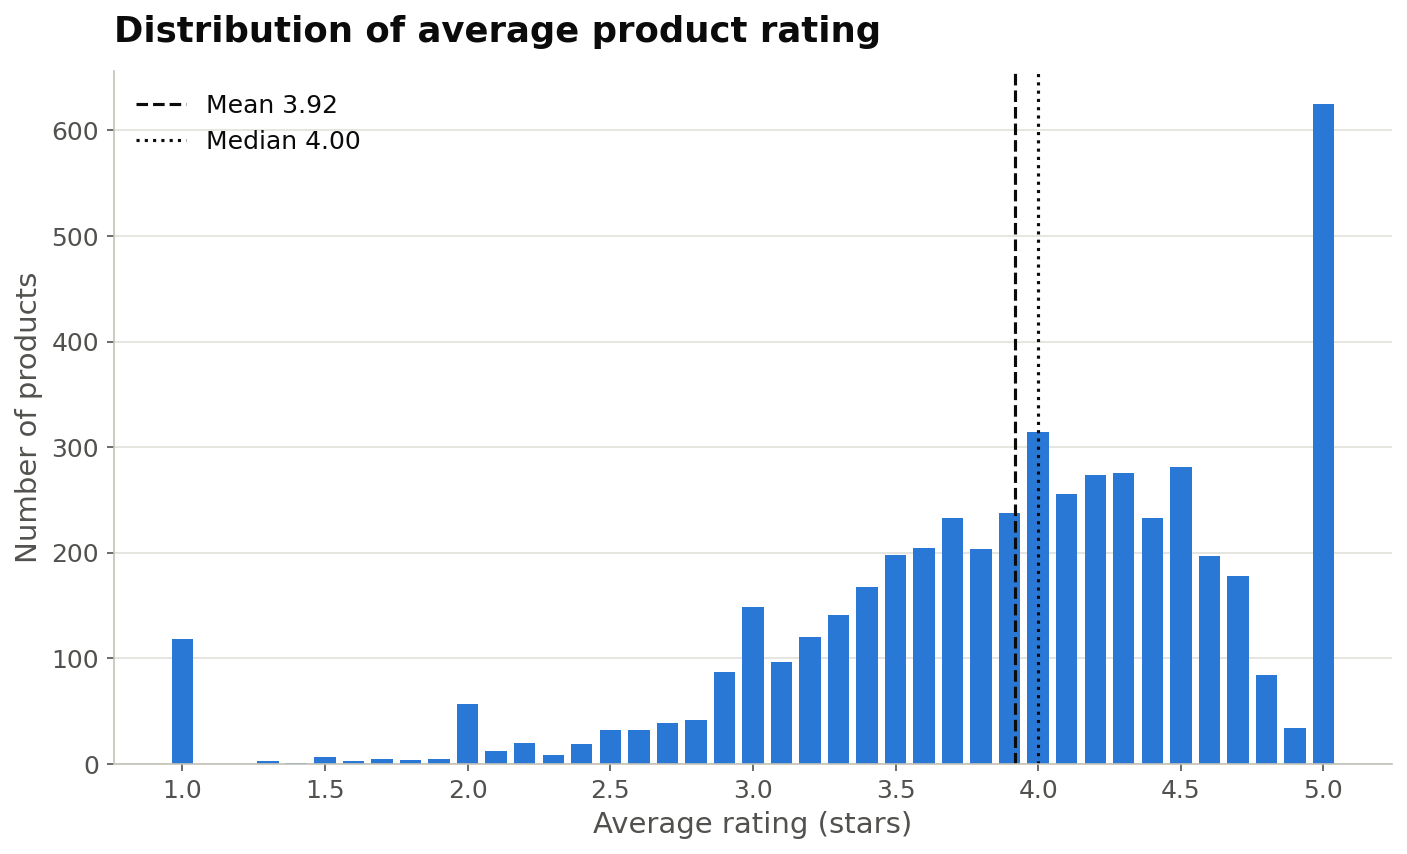

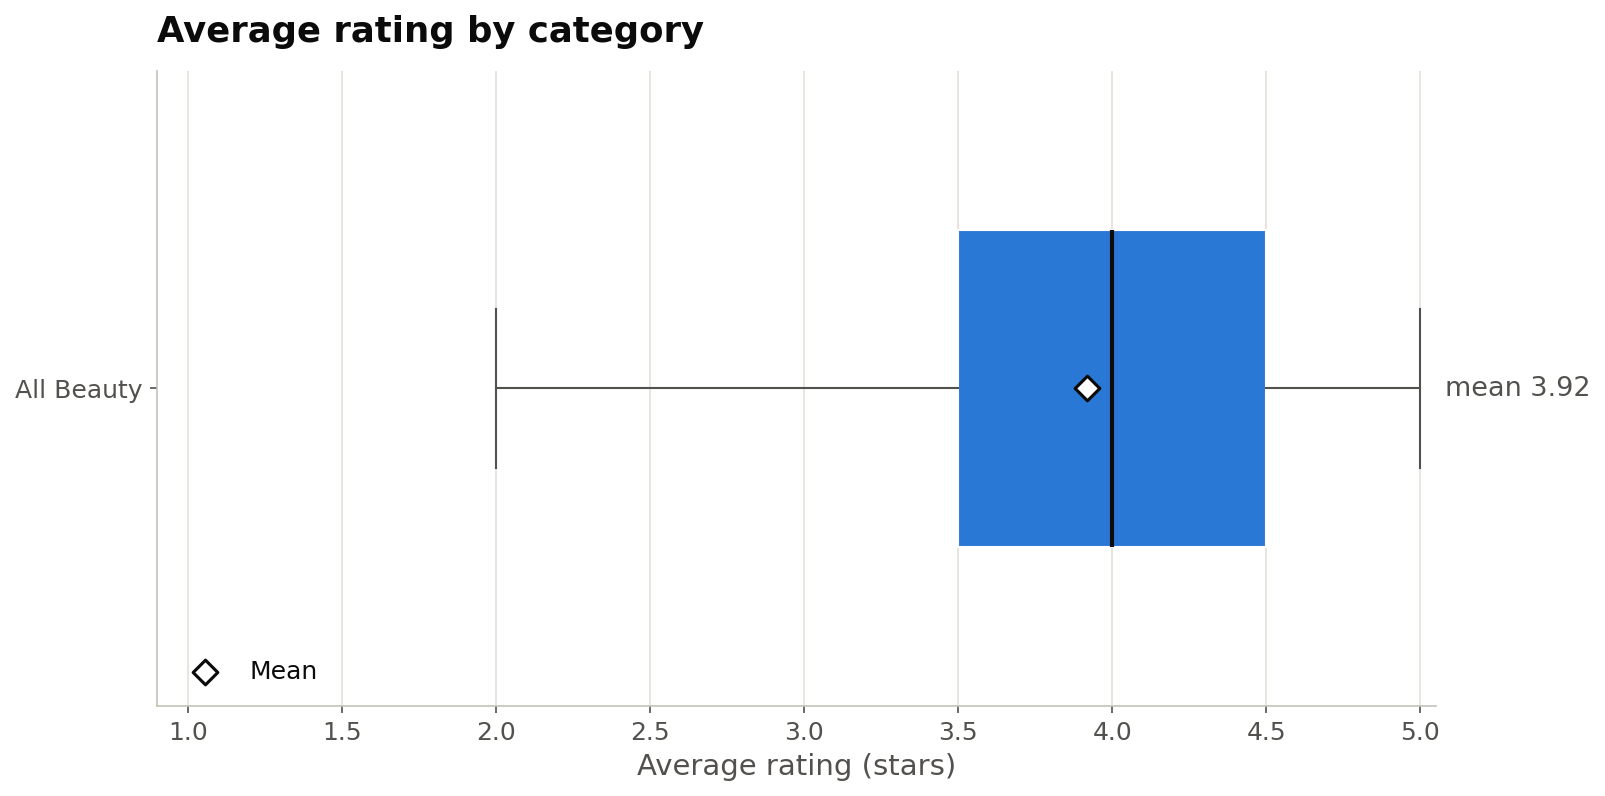

All EDA figure files: ['data\\processed\\pipeline\\quick\\figures\\01_rating_distribution.png', 'data\\processed\\pipeline\\quick\\figures\\02_rating_by_category.png', 'data\\processed\\pipeline\\quick\\figures\\03_category_counts.png', 'data\\processed\\pipeline\\quick\\figures\\04_price_vs_rating.png', 'data\\processed\\pipeline\\quick\\figures\\05_review_volume_vs_rating.png', 'data\\processed\\pipeline\\quick\\figures\\06_rating_by_volume_band.png', 'data\\processed\\pipeline\\quick\\figures\\07_correlation_heatmap.png']


In [5]:
figure_paths = pipeline.run_figures(clean_path)
for path in figure_paths[:2]:
    display(Image(filename=str(path), width=850))
print("All EDA figure files:", [str(path.relative_to(root)) for path in figure_paths])

## 5. Feature engineering

Michael Font (Person 2) owns `src.features`, the model-ready feature list and the split/preprocessor. Existing cleaning already creates price and rating-volume transforms and listing counts; the separate Submission 2 features will be integrated after his delivery.

The following placeholder reports its pending status without importing a missing module, inventing features or writing a model dataset. P1-c will replace it with the actual agreed API.

In [6]:
features_path = pipeline.run_features(clean_path)
assert features_path is None, "Update this skeleton when P1-c wires the feature stage."

features: SKIPPED; awaiting P2 features/split and P1-c integration


## 6. Modeling and evaluation

Rana Waleed Aftab (Person 3) owns the forthcoming `src.models` and modeling notebook. The team plans an 80/20 category-stratified split, five-fold validation on training data, baseline/Ridge/forest/boosting comparisons, tuning and a single final test evaluation; these are **plans, not completed results**.

P1-c will connect the delivered model API and Anthony's model charts. The placeholder below cannot train, tune or report test metrics.

In [7]:
model_results_path = pipeline.run_models(features_path)
assert model_results_path is None, "Update this skeleton when P1-c wires the model stage."

models: SKIPPED; awaiting P3 evaluation and P1-c integration


## 7. Findings and recommendations

Parker Fabian will integrate Rana's evaluated results and Anthony's charts in P1-c; all team members contribute interpretation for the final report. This skeleton establishes only that the available collection/cleaning/EDA workflow runs.

No best-model claim, held-out metric or seller recommendation is made here. After evaluation is merged, cite the actual `reports/tables/` files, compare against the baseline and connect each finding to a practical implication. Quick-mode outputs are for verification only.

## 8. Limitations and next steps

Michael Font drafts the report's Risks/Limitations; Parker integrates the team's final discussion. We use product metadata from a 2023 source snapshot, not review text. Store labels are not verified brands, prices may be missing, reviewers are self-selected, and associations do not establish causation.

The source review corpus spans May 1996-September 2023, but our metadata subset has no review timestamp column, so that is not a measured date range for these products. Cross-category duplicate handling and any minimum-rating threshold must follow Person 2's documented decisions. The quick sample covers only the first 5,000 entries of one category.

Next: integrate P2 features/split, P3 model evaluation and P4 model charts in P1-c; replace the placeholders, run the full workflow, record measured findings and verify from a fresh clone. Individual analytical notebooks remain the source for each owner's detailed work.